In [336]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt



def equation(t, y):
    x = y[0]
    v = y[1]

    return [v, -x]
solution = solve_ivp(
    equation,
    t_span=(0, 10),
    y0=[1,0],
    method="RK45"
)

print(solution.t)
print()
print(solution.y)

[0.00000000e+00 9.99000999e-04 1.09890110e-02 1.10889111e-01
 7.60150558e-01 1.69346562e+00 2.68189213e+00 3.66249862e+00
 4.57787220e+00 5.57710241e+00 6.53562405e+00 7.50732249e+00
 8.49647637e+00 9.42948990e+00 1.00000000e+01]

[[ 1.00000000e+00  9.99999501e-01  9.99939621e-01  9.93858100e-01
   7.24709764e-01 -1.22607648e-01 -8.96412983e-01 -8.66881284e-01
  -1.33005579e-01  7.61809510e-01  9.67792753e-01  3.37808419e-01
  -6.01037671e-01 -9.99858424e-01 -8.37545242e-01]
 [ 0.00000000e+00 -9.99000833e-04 -1.09887898e-02 -1.10661995e-01
  -6.89037713e-01 -9.92423098e-01 -4.43138753e-01  4.98428062e-01
   9.91048308e-01  6.47700170e-01 -2.51430149e-01 -9.41118675e-01
  -7.99102741e-01  7.31642727e-03  5.46146478e-01]]


In [337]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def equation(t, y):

    x = y[0]
    v = y[1]

    dxdt = v
    dvdt = -x

    return [dxdt, dvdt]

t_eval=np.linespace
solution = solve_ivp(
    equation,
    t_span=(0, 20),
    y0=[1, 0],
    t_eval=t_eval,
    method="RK45"
)
plt.plot(solution.t, solution.y[0], label="x(t)")
#plt.plot(solution.t, solution.y[1], label="v(t)")

plt.xlabel("t")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

AttributeError: module 'numpy' has no attribute 'linespace'

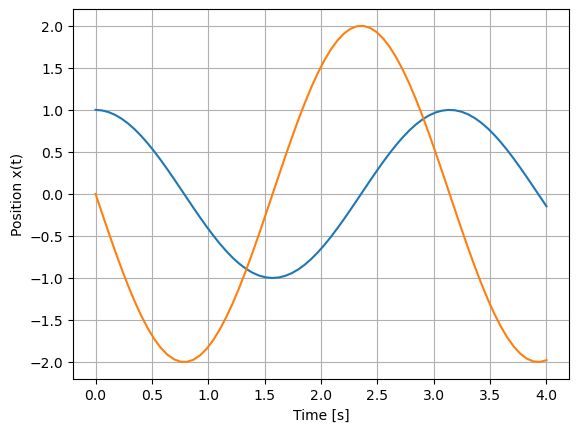

In [338]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


m = 2.0
k = 8.0


def equation(t, y):

    x = y[0]
    v = y[1]

    dxdt = v
    dvdt = -(k / m) * x

    return [dxdt, dvdt]


def stop_at_x_02(t, y):

    x = y[0]

    return x - 2.8


stop_at_x_02.terminal = True
stop_at_x_02.direction = -1


x0 = 1.0
v0 = 0.0


t_eval = np.linspace(0, 4, 70)


solution = solve_ivp(
    equation,
    t_span=(0, 4),
    y0=[x0, v0],
    events=stop_at_x_02,
    method="RK45",
    t_eval=t_eval
)


plt.plot(solution.t, solution.y[0])
plt.plot(solution.t, solution.y[1])

plt.xlabel("Time [s]")
plt.ylabel("Position x(t)")
plt.grid(0.25)
plt.show()

In [339]:
from ctypes import CDLL, POINTER, c_double
from pathlib import Path
import numpy as np

from scipy.integrate import solve_ivp

In [340]:
lib = CDLL("./libequations.dylib")

In [341]:
lib.equations.argtypes = [
    POINTER(c_double),  # varst
    POINTER(c_double),  # diffs
    c_double,           # impact_par
    POINTER(c_double),  # parbh
]

lib.equations.restype = None

In [342]:
def equations(
    varst: np.ndarray,
    impact_par: float,
    parbh: np.ndarray,
) -> np.ndarray:

    varst = np.ascontiguousarray(varst, dtype=np.float64)
    parbh = np.ascontiguousarray(parbh, dtype=np.float64)

    diffs = np.zeros_like(varst, dtype=np.float64)

    lib.equations(
        varst.ctypes.data_as(POINTER(c_double)),
        diffs.ctypes.data_as(POINTER(c_double)),
        c_double(impact_par),
        parbh.ctypes.data_as(POINTER(c_double)),
    )

    return diffs

In [343]:
varst = np.array([1.0, 2.0, 3.0, 4.0, 5.0])

parbh = np.array([1.0, 0.1])

impact_par = 0.11

diffs = equations(
    varst,
    impact_par,
    parbh
)

print(diffs)

[  3.           4.         -23.85449001 -24.00669752   0.13303955]


In [344]:
def geodesic(lam, varst):

    return equations(
        varst,
        impact_par,
        parbh
    )
    

def hit_disk(lam, varst):

    theta = varst[1]

    return theta - np.pi/2



hit_disk.terminal = True
hit_disk.direction = 1


t_eval = np.linspace(0, 63.8, 100)

varst0 = np.array([
    10000.0,    # r
    0.5,        # theta
    -1.0,       # dr/dlambda: inward
    0.001,      # dtheta/dlambda
    0.0         # phi
], dtype=np.float64)

parbh = np.array([1.0, 0.5])

impact_par = 0.11

solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 10000.0),
    y0=varst0,
    method="RK45",
    events=hit_disk,
    t_eval=t_eval
)

print(solution.t_events)
hit_state = solution.y_events[0][0]
print(hit_state)

[array([1546.87630111])]
[1.76201733e+04 1.57079633e+00 8.28004247e+00 3.24478592e-04
 2.01240309e-06]


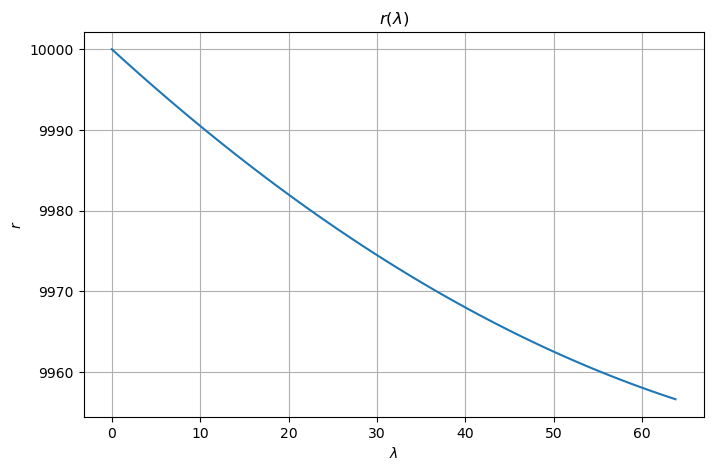

In [345]:
import matplotlib.pyplot as plt

lam = solution.t
r = solution.y[0]

plt.figure(figsize=(8, 5))
plt.plot(lam, r)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$r$")
plt.title(r"$r(\lambda)$")
plt.grid()
plt.show()

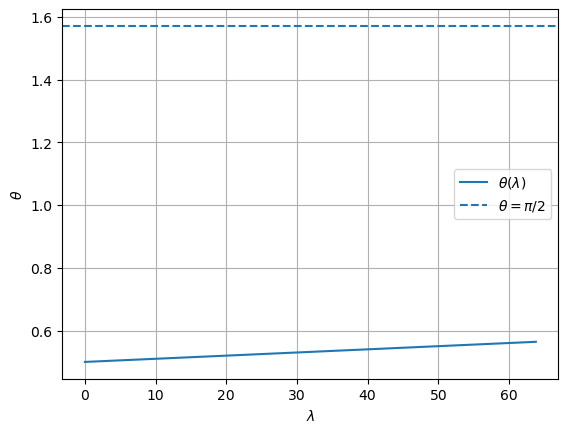

In [346]:
plt.plot(solution.t, solution.y[1], label=r"$\theta(\lambda)$")

plt.axhline(
    np.pi/2,
    linestyle="--",
    label=r"$\theta=\pi/2$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\theta$")
plt.legend()
plt.grid()
plt.show()

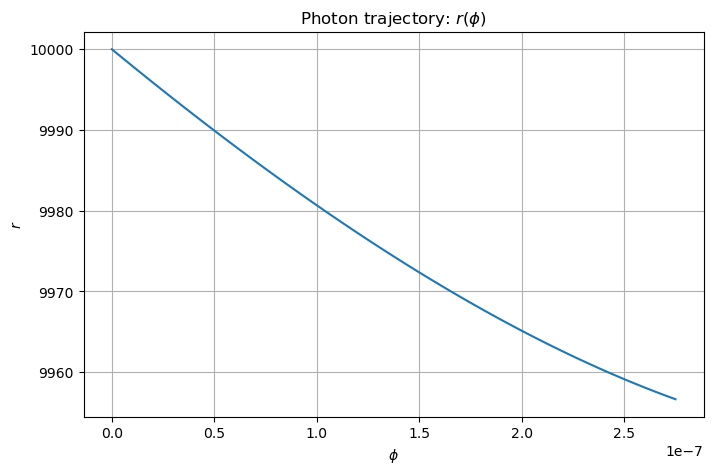

In [347]:
phi=solution.y[4]
plt.figure(figsize=(8, 5))
plt.plot(phi, r)
plt.xlabel(r"$\phi$")
plt.ylabel(r"$r$")
plt.title(r"Photon trajectory: $r(\phi)$")
plt.grid()
plt.show()

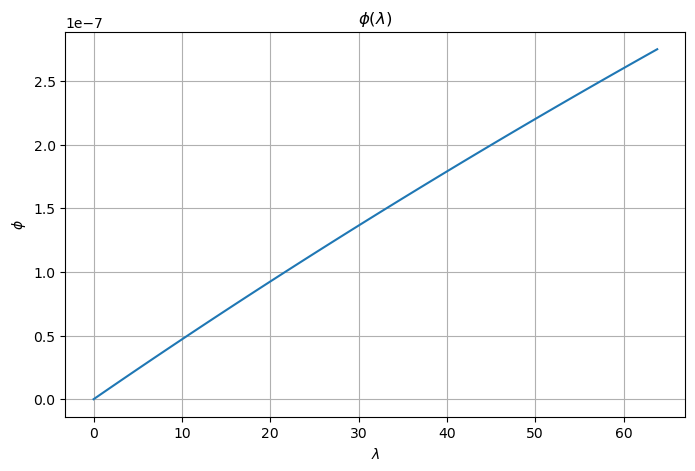

In [348]:
phi = solution.y[4]
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]


plt.figure(figsize=(8, 5))
plt.plot(lam, phi)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\phi$")
plt.title(r"$\phi(\lambda)$")
plt.grid()
plt.show()

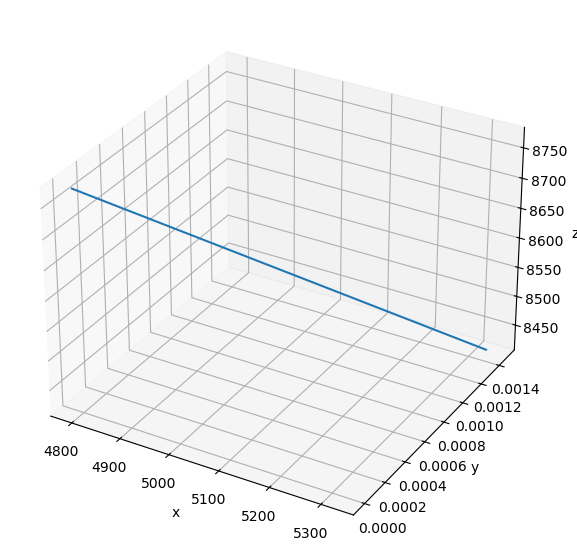

In [349]:
from mpl_toolkits.mplot3d import Axes3D

theta = solution.y[1]
phi = solution.y[4]

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.show()

In [350]:
theta_values = np.linspace(0.8, 1.2, 5)

solutions = []

for theta0 in theta_values:

    varst0 = np.array([
        10000.0,
        theta0,
        -1.0,
        0.01,
        0.0
    ])

    solution = solve_ivp(
        geodesic,
        t_span=(0.0, 10000.0),
        y0=varst0,
        method="RK45",
        events=hit_disk,
        t_eval=t_eval
    )

    solutions.append(solution)

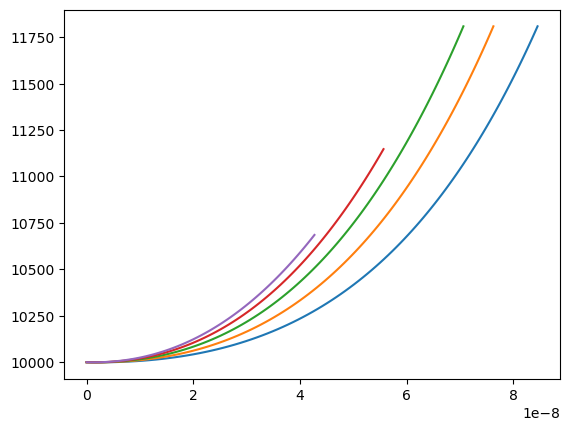

In [351]:
for solution in solutions:

    r = solution.y[0]
    theta = solution.y[1]
    phi = solution.y[4]

    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)

    plt.plot(solution.y[4], solution.y[0])

In [352]:
def geodesic(lam, varst):

    return equations(
        varst,
        impact_par,
        parbh
    )


def hit_disk(lam, varst):

    theta = varst[1]

    return theta - np.pi / 2


hit_disk.terminal = True
hit_disk.direction = 0


t_eval = np.linspace(0, 63.8, 100)

varst0 = np.array([
    10000.0,   # r
    0.5,       # theta
    0.0,       # dr/dlambda
    0.001,     # dtheta/dlambda
    0.0        # phi
], dtype=np.float64)

parbh = np.array([1.0, 0.5], dtype=np.float64)

impact_par = 0.11

solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 10000.0),
    y0=varst0,
    method="RK45",
    events=hit_disk,
    t_eval=t_eval
)

print(solution.t_events)

if len(solution.t_events[0]) > 0:
    hit_state = solution.y_events[0][0]
    print("Photon hit the disk:")
    print(hit_state)
else:
    print("The photon did not reach the disk.")

[array([1829.36163831])]
Photon hit the disk:
[2.08330566e+04 1.57079633e+00 8.75800871e+00 2.30334471e-04
 2.01274681e-06]


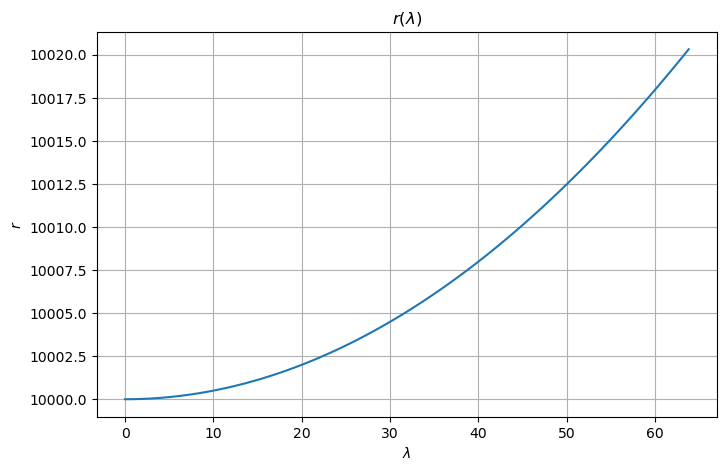

In [353]:
import matplotlib.pyplot as plt

lam = solution.t
r = solution.y[0]

plt.figure(figsize=(8, 5))
plt.plot(lam, r)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$r$")
plt.title(r"$r(\lambda)$")
plt.grid()
plt.show()

### Re writing code

In [354]:
def initial_photon_state(
    alpha,
    beta,
    d,
    inclination
):

    # Initial radial coordinate
    r_j = np.sqrt(
        d**2
        + alpha**2
        + beta**2
    )

    # Initial polar coordinate
    theta_j = np.arccos(
        (
            d * np.cos(inclination)
            + beta * np.sin(inclination)
        )
        / r_j
    )

    # Initial azimuthal coordinate
    phi_j = np.arctan2(
        alpha,
        d * np.sin(inclination)
        - beta * np.cos(inclination)
    )

    # Radial velocity
    dr_dlambda_j = -d / r_j

    # Polar velocity
    numerator = (
        -np.cos(inclination)
        + (
            d / r_j**2
        )
        * (
            d * np.cos(inclination)
            + beta * np.sin(inclination)
        )
    )

    denominator = np.sqrt(
        r_j**2
        - (
            d * np.cos(inclination)
            + beta * np.sin(inclination)
        )**2
    )

    dtheta_dlambda_j = (
        numerator / denominator
    )

    # Azimuthal velocity
    dphi_dlambda_j = (
        -alpha * np.sin(inclination)
        / (
            alpha**2
            + (
                d * np.sin(inclination)
                - beta * np.cos(inclination)
            )**2
        )
    )

    # Your C code uses:
    #
    # dphi/dlambda =
    # impact_par / (r^2 sin^2(theta))
    #
    impact_par = (
        r_j**2
        * np.sin(theta_j)**2
        * dphi_dlambda_j
    )

    varst0 = np.array([
        r_j,
        theta_j,
        dr_dlambda_j,
        dtheta_dlambda_j,
        phi_j
    ])

    return varst0, impact_par

# bitta pixel uchun

In [355]:
d = 10000.0
inclination = 0.5

alpha = 10.0
beta = 5.0

varst0, impact_par = initial_photon_state(
    alpha,
    beta,
    d,
    inclination
)

print("varst0 =", varst0)
print("impact parameter =", impact_par)

varst0 = [ 1.00000062e+04  4.99500916e-01 -9.99999375e-01  4.98166127e-08
  2.08773740e-03]
impact parameter = -4.794255386042031


In [356]:
solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 10000.0),
    y0=varst0,
    method="RK45",
    events=hit_disk,
    t_eval=t_eval
)

In [357]:
def f_metric(r, mpar, qpar):

    return 1.0-(2.0*mpar / r)*(1.0-np.tanh(qpar**2 / (2.0*mpar*r)))

mpar=1.0
qpar=0.5
r0 = varst0[0]
theta0 = varst0[1]
dr0 = varst0[2]
dtheta0 = varst0[3]

f0 = f_metric(
    r0,
    mpar,
    qpar
)

gtt0 = -f0
grr0 = 1.0 / f0
gthth0 = r0**2
gpp0 = r0**2 * np.sin(theta0)**2

kt0 = 1.0 / f0

kphi0 = (
    impact_par
    / gpp0
)

null0 = (
    gtt0 * kt0**2
    + grr0 * dr0**2
    + gthth0 * dtheta0**2
    + gpp0 * kphi0**2
)

print("r0 =", r0)
print("theta0 =", theta0)
print("dr/dlambda =", dr0)
print("dtheta/dlambda =", dtheta0)
print("kphi =", kphi0)
print("Null condition =", null0)

r0 = 10000.006249998047
theta0 = 0.4995009163725095
dr/dlambda = -0.999999375000586
dtheta/dlambda = 4.981661270245479e-08
kphi = -2.0896438685600315e-07
Null condition = -2.5004635093620597e-10


#### Boshlang'ich shartini va nishon (b impactni but just static-spheric-symmetric metric) kirita olamiz
## $$ b = \frac{L_z}{E} = r_j^2 \sin^2\theta_j\dot{\phi}_j$$

In [358]:
varst0 = np.array([
    1.00000062e+04,
    4.99500916e-01,
   -9.99999375e-01,
    4.98166127e-08,
    2.08773740e-03
])

impact_par = -4.794255

def geodesic(lam, varst):

    return equations(
        varst,
        impact_par,
        parbh
    )
t_eval = np.linspace(0.0, 10000.0, 1000)

solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 10000.0),
    y0=varst0,
    method="RK45",
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)
r_values = solution.y[0]
theta_values = solution.y[1]
phi_values = solution.y[4]

## muhim tekshiruv qiymatlar
print("Initial r =", r_values[0])
print("Final r =", r_values[-1])

print("Initial theta =", theta_values[0])
print("Final theta =", theta_values[-1])

Initial r = 10000.0062
Final r = 10.089200315641598
Initial theta = 0.499500916
Final theta = 1.877352221731691


### horizon topamiz (M(mpar) = 1 va q(qpar)=0.5 uchun albatta!!!)

In [359]:
from scipy.optimize import brentq

def f_metric(r, mpar, qpar):

    return 1.0 - (
        2.0 * mpar / r
    ) * (
        1.0
        - np.tanh(
            qpar**2
            / (2.0 * mpar * r)
        )
    )

In [360]:
r_h = brentq(
    lambda r: f_metric(r, mpar, qpar),
    0.1,
    10.0
)

print("Horizon radius =", r_h)

Horizon radius = 1.8662408357449956


### eventlarni yozamiz

In [361]:
def hit_disk(lam, varst,impact_par, parbh):

    return varst[1] - np.pi / 2


hit_disk.terminal = True
hit_disk.direction = 1

def hit_horizon(lam, varst,impact_par, parbh):

    return varst[0] - (r_h + 1e-6)


hit_horizon.terminal = True
hit_horizon.direction = -1

def escaped(lam, varst,impact_par, parbh):

    return varst[0] - 100000.0


escaped.terminal = True
escaped.direction = 1

### runge-kutta flehberg rk45 ishlatamiz geodesicni yechamiz

In [362]:
solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 100000.0),
    y0=varst0,
    method="RK45",
    events=[
        hit_disk,
        hit_horizon,
        escaped
    ],
    rtol=1e-9,
    atol=1e-11
)

print("Disk event:", solution.t_events[0])
print("Horizon event:", solution.t_events[1])
print("Escape event:", solution.t_events[2])

TypeError: hit_disk() missing 2 required positional arguments: 'impact_par' and 'parbh'

In [363]:
if len(solution.t_events[0]) > 0:

    hit_state = solution.y_events[0][0]

    print("Photon hit the disk")
    print("r_hit =", hit_state[0])
    print("phi_hit =", hit_state[4])

elif len(solution.t_events[1]) > 0:

    print("Photon was captured by the black hole")

elif len(solution.t_events[2]) > 0:

    print("Photon escaped to infinity")

TypeError: 'NoneType' object is not subscriptable

## bu yuqorida faqat screen bitta pixeli uchun ko'rdik

In [364]:
alpha_values = np.linspace(-50, 50, 41)
beta_values = np.linspace(-50, 50, 41)

classification = np.zeros(
    (
        len(beta_values),
        len(alpha_values)
    ),
    dtype=int
)

def geodesic(lam, varst, impact_par, parbh):

    return equations(
        varst,
        impact_par,
        parbh
    )

for beta_index, beta in enumerate(beta_values):

    for alpha_index, alpha in enumerate(alpha_values):

        varst0, impact_par = initial_photon_state(
            alpha,
            beta,
            d,
            inclination
        )

        solution = solve_ivp(
            fun=geodesic,
            t_span=(0.0, 100000.0),
            y0=varst0,
            args=(impact_par, parbh),
            method="RK45",
            events=[
                hit_disk,
                hit_horizon,
                escaped
            ],
            rtol=1e-9,
            atol=1e-11
        )

        if len(solution.t_events[0]) > 0:

            classification[
                beta_index,
                alpha_index
            ] = 2

        elif len(solution.t_events[1]) > 0:

            classification[
                beta_index,
                alpha_index
            ] = 1

        elif len(solution.t_events[2]) > 0:

            classification[
                beta_index,
                alpha_index
            ] = 3

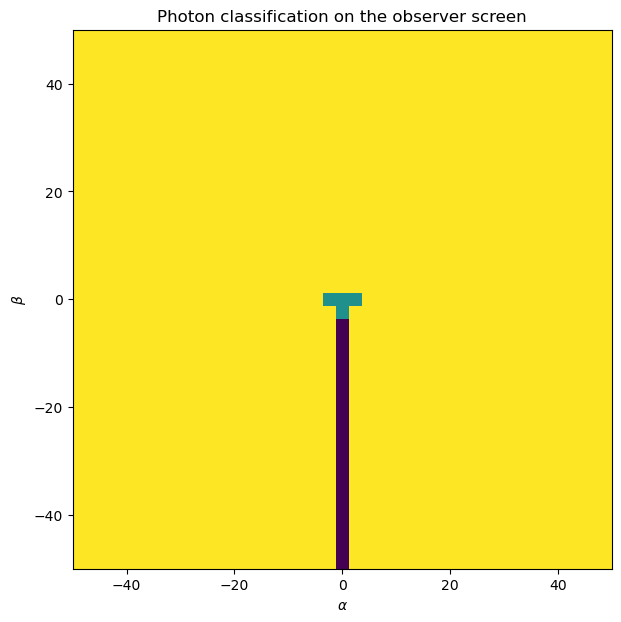

In [365]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))

plt.imshow(
    classification,
    extent=[
        alpha_values[0],
        alpha_values[-1],
        beta_values[0],
        beta_values[-1]
    ],
    origin="lower",
    aspect="equal"
)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\beta$")
plt.title("Photon classification on the observer screen")

plt.show()

In [366]:
for alpha, beta in [
    (0, 0),
    (10, 0),
    (-10, 0),
    (0, 10),
    (0, -10),
    (20, 0),
    (0, 20)
]:

    varst0, impact_par = initial_photon_state(
        alpha,
        beta,
        d,
        inclination
    )

    print(
        f"alpha={alpha}, beta={beta}"
    )
    print(
        "r0 =", varst0[0],
        "theta0 =", varst0[1]
    )
    print(
        "dr/dlambda =", varst0[2],
        "dtheta/dlambda =", varst0[3]
    )
    print(
        "impact parameter =", impact_par
    )
    print()

alpha=0, beta=0
r0 = 10000.0 theta0 = 0.4999999999999999
dr/dlambda = -1.0 dtheta/dlambda = 0.0
impact parameter = 0.0

alpha=10, beta=0
r0 = 10000.00499999875 theta0 = 0.5000009152424075
dr/dlambda = -0.9999995000003751 dtheta/dlambda = -1.8304819091018426e-10
impact parameter = -4.794255386042025

alpha=-10, beta=0
r0 = 10000.00499999875 theta0 = 0.5000009152424075
dr/dlambda = -0.9999995000003751 dtheta/dlambda = -1.8304819091018426e-10
impact parameter = 4.794255386042025

alpha=0, beta=10
r0 = 10000.00499999875 theta0 = 0.4990000003333333
dr/dlambda = -0.9999995000003751 dtheta/dlambda = 9.999990000010791e-08
impact parameter = 0.0

alpha=0, beta=-10
r0 = 10000.00499999875 theta0 = 0.5009999996666665
dr/dlambda = -0.9999995000003751 dtheta/dlambda = -9.999990000006728e-08
impact parameter = 0.0

alpha=20, beta=0
r0 = 10000.01999998 theta0 = 0.500003660952194
dr/dlambda = -0.9999980000059999 dtheta/dlambda = -7.321857889644432e-10
impact parameter = -9.58851077208406

alpha=0, beta

#  N O R M A L I Z E D 4-momentums 

1-step# initial photon geometry

In [367]:
import numpy as np


def initial_photon_geometry(
    alpha,
    beta,
    d,
    inclination
):
    """
    Construct the initial photon position and spatial momentum
    from the observer screen coordinates (alpha,beta).
    """

    # ---------------------------------------------------------
    # Initial position
    # ---------------------------------------------------------

    r0 = np.sqrt(
        d**2 +
        alpha**2 +
        beta**2
    )

    theta0 = np.arccos(
        (
            d*np.cos(inclination)
            +
            beta*np.sin(inclination)
        ) / r0
    )

    phi0 = np.arctan2(
        alpha,
        d*np.sin(inclination)
        -
        beta*np.cos(inclination)
    )

    # ---------------------------------------------------------
    # Spatial momentum
    # ---------------------------------------------------------

    kr = -d / r0

    numerator = (
        -np.cos(inclination)
        +
        (
            d / r0**2
        )
        *
        (
            d*np.cos(inclination)
            +
            beta*np.sin(inclination)
        )
    )

    denominator = np.sqrt(
        r0**2
        -
        (
            d*np.cos(inclination)
            +
            beta*np.sin(inclination)
        )**2
    )

    ktheta = numerator / denominator

    kphi = (
        -alpha*np.sin(inclination)
        /
        (
            alpha**2
            +
            (
                d*np.sin(inclination)
                -
                beta*np.cos(inclination)
            )**2
        )
    )

    return (
        r0,
        theta0,
        phi0,
        kr,
        ktheta,
        kphi
    )

In [368]:
### test check
d = 10000
inclination = np.deg2rad(60)

r0, theta0, phi0, kr, ktheta, kphi = initial_photon_geometry(
    10,
    5,
    d,
    inclination
)

print(r0)
print(theta0)
print(phi0)
print(kr)
print(ktheta)
print(kphi)

10000.006249998047
1.0466978402465152
0.0011550334543208862
-0.999999375000586
4.994215255987951e-08
-1.155365952454481e-07


In [369]:
print(hasattr(lib, "gmetric"))

True


In [370]:
## 2-qadam metric()ni Pythonda tanishtiramiz.
from ctypes import (
    POINTER,
    c_double
)

Matrix4 = (c_double * 4) * 4

lib.gmetric.argtypes = [
    c_double,
    c_double,
    POINTER(Matrix4),
    POINTER(c_double)
]

lib.gmetric.restype = None

In [371]:
# 3-qadam. haqiqiy wrapper yozamiz
def metric_components(
    r,
    theta,
    parbh
):

    g = Matrix4()

    parbh_array = np.ascontiguousarray(
        parbh,
        dtype=np.float64
    )

    lib.gmetric(
        c_double(r),
        c_double(theta),
        g,
        parbh_array.ctypes.data_as(
            POINTER(c_double)
        )
    )

    return np.array(g)

In [372]:
# tekshirib olamiz
g = metric_components(
    r0,
    theta0,
    parbh
)

print(g)

[[-9.99800003e-01  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  1.00020004e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000125e+08  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  7.49568050e+07]]


In [373]:
# 3-qadam umumiy kerr uchun yozamiz photon motion va kt ni aniqlaymiz kv tenglama qilib
def solve_null_condition(
    g,
    kr,
    ktheta,
    kphi
):
    """
    Compute k^t from the null condition

        g_{μν} k^μ k^ν = 0

    Works for both static and stationary metrics.
    """

    gtt = g[0, 0]
    gtp = g[0, 3]
    grr = g[1, 1]
    gthth = g[2, 2]
    gpp = g[3, 3]

    A = gtt

    B = 2.0 * gtp * kphi

    C = (
        grr * kr**2
        +
        gthth * ktheta**2
        +
        gpp * kphi**2
    )

    discriminant = B**2 - 4.0*A*C

    if discriminant < 0:
        raise ValueError(
            "Negative discriminant in null condition."
        )

    sqrtD = np.sqrt(discriminant)

    kt1 = (-B + sqrtD)/(2*A)

    kt2 = (-B - sqrtD)/(2*A)

    return kt1, kt2

# Computing the $k^t-?$ $g_{\mu\nu}k^{\mu}k^{\nu}=0$ for 

In [374]:
# test qilamiz
kt1, kt2 = solve_null_condition(
    g,
    kr,
    ktheta,
    kphi
)

print("kt1 =", kt1)
print("kt2 =", kt2)

kt1 = -1.0002000372569313
kt2 = 1.0002000372569313


In [375]:
# 4-qadam : Conserved quantites ray-tracing uchun E=-p_t va Lz = p_]phi
def conserved_quantities(
    g,
    kt,
    kphi
):
    """
    Compute conserved quantities

        E  = -p_t
        Lz =  p_phi

    for a stationary axisymmetric spacetime.
    """

    gtt = g[0, 0]
    gtp = g[0, 3]
    gpp = g[3, 3]

    # Conserved energy
    E = -(
        gtt * kt
        +
        gtp * kphi
    )

    # Conserved angular momentum
    Lz = (
        gpp * kphi
        +
        gtp * kt
    )

    impact_par = Lz / E

    return E, Lz, impact_par

In [376]:
# tekshirib olamiz kattaliklarni
kt = kt2

E, Lz, impact_par = conserved_quantities(
    g,
    kt,
    kphi
)

print("E =", E)
print("Lz =", Lz)
print("impact =", impact_par)

E = 0.9999999998750018
Lz = -8.660254037844386
impact = -8.660254038926903


In [377]:
# Endi oxirgi boshlang'ich shart funksiyasini yozamiz
# bu funksiya tepadagi initial_photon_state() ni to'liq almashtiradi
def initial_photon_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
):
    """
    Construct normalized initial conditions for the geodesic solver.
    """

    # --------------------------------------------------
    # Geometry
    # --------------------------------------------------

    (
        r0,
        theta0,
        phi0,
        kr,
        ktheta,
        kphi
    ) = initial_photon_geometry(
        alpha,
        beta,
        d,
        inclination
    )

    # --------------------------------------------------
    # Metric
    # --------------------------------------------------

    g = metric_components(
        r0,
        theta0,
        parbh
    )

    # --------------------------------------------------
    # Null condition
    # --------------------------------------------------

    kt_plus, kt_minus = solve_null_condition(
        g,
        kr,
        ktheta,
        kphi
    )

    # Choose the future-directed solution
    candidates = [kt_plus, kt_minus]
    positive = [k for k in candidates if k > 0]

    if len(positive) != 1:
        raise ValueError("Could not identify the future-directed solution.")

    kt = positive[0]

    # --------------------------------------------------
    # Conserved quantities
    # --------------------------------------------------

    E, Lz, impact_par = conserved_quantities(
        g,
        kt,
        kphi
    )

    # --------------------------------------------------
    # Normalize affine parameter
    # --------------------------------------------------

    kr /= E
    ktheta /= E

    varst0 = np.array([
        r0,
        theta0,
        kr,
        ktheta,
        phi0
    ])

    return varst0, impact_par

In [378]:
# normalizatsiya
def normalize_initial_state(
    r0,
    theta0,
    phi0,
    kr,
    ktheta,
    E
):
    """
    Normalize the affine parameter:

        λ' = E λ

    Therefore

        dr/dλ' = (dr/dλ)/E
        dθ/dλ' = (dθ/dλ)/E
    """

    kr /= E
    ktheta /= E

    varst0 = np.array([
        r0,
        theta0,
        kr,
        ktheta,
        phi0
    ])

    return varst0

In [379]:
alpha = 3.
beta = 0.001

(
    r0,
    theta0,
    phi0,
    kr,
    ktheta,
    kphi
) = initial_photon_geometry(
    alpha,
    beta,
    d,
    inclination
)

g = metric_components(
    r0,
    theta0,
    parbh
)

kt1, kt2 = solve_null_condition(
    g,
    kr,
    ktheta,
    kphi
)

# Future-directed solution
kt = kt2

E, Lz, impact_par = conserved_quantities(
    g,
    kt,
    kphi
)

varst0 = normalize_initial_state(
    r0,
    theta0,
    phi0,
    kr,
    ktheta,
    E
)

print("varst0 =", varst0)
print("impact =", impact_par)

varst0 = [ 1.00000005e+04  1.04719748e+00 -9.99999955e-01  4.80384654e-12
  3.46410168e-04]
impact = -2.5980762113766986


In [380]:
def build_initial_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
):
    """
    Build normalized initial conditions for the geodesic solver.
    """

    # -------------------------------------------------
    # 1. Observer geometry
    # -------------------------------------------------
    (
        r0,
        theta0,
        phi0,
        kr,
        ktheta,
        kphi
    ) = initial_photon_geometry(
        alpha,
        beta,
        d,
        inclination
    )

    # -------------------------------------------------
    # 2. Metric
    # -------------------------------------------------
    g = metric_components(
        r0,
        theta0,
        parbh
    )

    # -------------------------------------------------
    # 3. Solve null condition
    # -------------------------------------------------
    kt1, kt2 = solve_null_condition(
        g,
        kr,
        ktheta,
        kphi
    )

    # Choose the future-directed solution
    if kt1 > 0:
        kt = kt1
    elif kt2 > 0:
        kt = kt2
    else:
        raise ValueError("No future-directed solution found.")

    # -------------------------------------------------
    # 4. Conserved quantities
    # -------------------------------------------------
    E, Lz, impact_par = conserved_quantities(
        g,
        kt,
        kphi
    )

    # -------------------------------------------------
    # 5. Normalize affine parameter
    # -------------------------------------------------
    varst0 = normalize_initial_state(
        r0,
        theta0,
        phi0,
        kr,
        ktheta,
        E
    )

    return varst0, impact_par

In [381]:
varst0, impact_par = build_initial_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
)

print(varst0)
print(impact_par)

[ 1.00000005e+04  1.04719748e+00 -9.99999955e-01  4.80384654e-12
  3.46410168e-04]
-2.5980762113766986


In [382]:
varst0, impact_par = initial_photon_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
)

In [383]:
varst0, impact_par = build_initial_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
)

In [384]:
# bitta photon uchun qaraymiz
def geodesic(lam, varst, impact_par, parbh):

    return equations(
        varst,
        impact_par,
        parbh
    )

In [385]:
alpha = 3.
beta = 0.001

varst0, impact_par = build_initial_state(
    alpha,
    beta,
    d,
    inclination,
    parbh
)

print("varst0 =", varst0)
print("impact =", impact_par)

varst0 = [ 1.00000005e+04  1.04719748e+00 -9.99999955e-01  4.80384654e-12
  3.46410168e-04]
impact = -2.5980762113766986


In [386]:
solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 100000.0),
    y0=varst0,
    args=(impact_par, parbh),
    method="RK45",
    events=[
        hit_disk,
        hit_horizon,
        escaped
    ],
    rtol=1e-9,
    atol=1e-11
)

In [387]:
print("Disk :", solution.t_events[0])
print("Horizon :", solution.t_events[1])
print("Escape :", solution.t_events[2])

Disk : [9999.15891883]
Horizon : []
Escape : []


In [388]:
if len(solution.t_events[0]) > 0:

    hit = solution.y_events[0][0]

    print("r_hit =", hit[0])
    print("theta_hit =", hit[1])
    print("phi_hit =", hit[4])

r_hit = 2.179181172830301
theta_hit = 1.5707963267949816
phi_hit = -1.570129650973967


In [389]:
# koproq grid qilib koramiz
alpha_values = np.linspace(-20,20,51)

beta_values = np.linspace(-20,20,51)

In [390]:
#klassifikatsiya matritsasini yar
classification = np.zeros(
    (len(beta_values), len(alpha_values)),
    dtype=int
)

In [391]:
for j, beta in enumerate(beta_values):

    print(f"{j+1}/{len(beta_values)}")

    for i, alpha in enumerate(alpha_values):

        varst0, impact_par = build_initial_state(
            alpha,
            beta,
            d,
            inclination,
            parbh
        )

        solution = solve_ivp(
            geodesic,
            (0.0, 100000.0),
            varst0,
            args=(impact_par, parbh),
            method="RK45",
            events=[
                hit_disk,
                hit_horizon,
                escaped
            ],
            rtol=1e-9,
            atol=1e-11
        )

        if len(solution.t_events[1]) > 0:
            classification[j, i] = 1

        elif len(solution.t_events[0]) > 0:
            classification[j, i] = 2

        elif len(solution.t_events[2]) > 0:
            classification[j, i] = 3

1/51
2/51
3/51
4/51
5/51
6/51
7/51
8/51
9/51
10/51
11/51
12/51
13/51
14/51
15/51
16/51
17/51
18/51
19/51
20/51
21/51
22/51
23/51
24/51
25/51
26/51
27/51
28/51
29/51
30/51
31/51
32/51
33/51
34/51
35/51
36/51
37/51
38/51
39/51
40/51
41/51
42/51
43/51
44/51
45/51
46/51
47/51
48/51
49/51
50/51
51/51


In [392]:
print("Horizon photons :", np.sum(classification == 1))
print("Disk photons    :", np.sum(classification == 2))
print("Escape photons  :", np.sum(classification == 3))
print("Unclassified    :", np.sum(classification == 0))

Horizon photons : 38
Disk photons    : 2544
Escape photons  : 0
Unclassified    : 19


In [393]:
for j, beta in enumerate(beta_values):

    for i, alpha in enumerate(alpha_values):

        if classification[j, i] == 1:

            print(alpha, beta)

0.0 -4.799999999999999
0.0 -4.0
-1.5999999999999979 -3.1999999999999993
-0.7999999999999972 -3.1999999999999993
0.0 -3.1999999999999993
0.8000000000000007 -3.1999999999999993
1.6000000000000014 -3.1999999999999993
-2.3999999999999986 -2.3999999999999986
-1.5999999999999979 -2.3999999999999986
-0.7999999999999972 -2.3999999999999986
0.0 -2.3999999999999986
0.8000000000000007 -2.3999999999999986
1.6000000000000014 -2.3999999999999986
2.400000000000002 -2.3999999999999986
-2.3999999999999986 -1.5999999999999979
-1.5999999999999979 -1.5999999999999979
-0.7999999999999972 -1.5999999999999979
0.0 -1.5999999999999979
0.8000000000000007 -1.5999999999999979
1.6000000000000014 -1.5999999999999979
2.400000000000002 -1.5999999999999979
-2.3999999999999986 -0.7999999999999972
-1.5999999999999979 -0.7999999999999972
-0.7999999999999972 -0.7999999999999972
0.0 -0.7999999999999972
0.8000000000000007 -0.7999999999999972
1.6000000000000014 -0.7999999999999972
2.400000000000002 -0.7999999999999972
-2.399

In [394]:
solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 100000.0),
    y0=varst0,
    args=(impact_par, parbh),
    method="RK45",
    events=[
        hit_disk,
        hit_horizon,
        escaped
    ],
    dense_output=True,
    rtol=1e-9,
    atol=1e-11
)

In [395]:
lam = solution.t

r = solution.y[0]

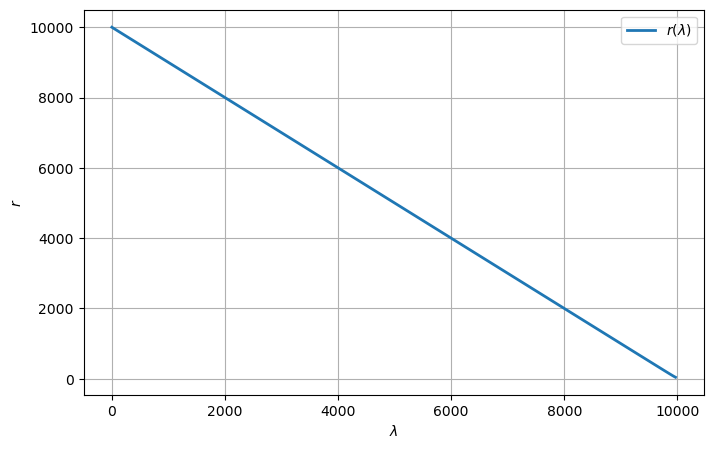

In [396]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    lam,
    solution.y[0],
    linewidth=2,
    label=r"$r(\lambda)$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$r$")
plt.grid(True)

plt.legend()

plt.show()

In [398]:
r_h

1.8662408357449956